# Дробная диффузия по времени — Орлов

$$D_t^\alpha u=u_{xx},\quad x\in[0,1],\quad t\in[0,1],\quad u(0,t)=u(1,t)=0.$$

Производная Капуто, $0.2\leq\alpha\leq0.9$. Сетка: 128 узлов, включая края, и 500 шагов по времени. Неявная L1-схема и центральные разности по пространству.

Ноутбук использует код из `src/` и готовый локальный датасет. Генерация датасета: `python -m src.generate_dataset`.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'src' / 'solver.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.solver import solve_l1
from src.reference import exact_sine_solution
from src.validate import run_validation

## Проверка по Миттаг-Леффлеру

Для $u_0(x)=\sin(\pi x)$ точное решение:
$$u(x,t)=E_{\alpha,1}(-\pi^2t^\alpha)\sin(\pi x).$$

Показываем ошибки как при $T=1$, так и на всём временном интервале. Вблизи нуля решение имеет слабую временную особенность. Относительная $L_2$-ошибка считается по пространственной сетке при $T=1$.

In [2]:
metrics = run_validation(ROOT / 'results')
header = '| α | Абсолютная ошибка при T=1 | Относительная L2 при T=1 | Максимальная ошибка по времени |\n|---|---|---|---|'
rows = [f"| {m['alpha']} | {m['final_linf']:.4e} | {m['final_relative_l2']:.4%} | {m['max_linf_over_time']:.4e} |" for m in metrics]
display(Markdown(header + '\n' + '\n'.join(rows)))

Validation:
{'alpha': 0.2, 'n_x': 128, 'n_steps': 500, 'final_linf': 1.8729118927279798e-05, 'final_relative_l2': 0.00023244380133522554, 'max_linf_over_time': 0.03858317002909467, 'time_of_max_error': 0.002}
{'alpha': 0.35, 'n_x': 128, 'n_steps': 500, 'final_linf': 2.66216900731836e-05, 'final_relative_l2': 0.0003819163644949691, 'max_linf_over_time': 0.07800454317179495, 'time_of_max_error': 0.002}
{'alpha': 0.5, 'n_x': 128, 'n_steps': 500, 'final_linf': 3.122442557471766e-05, 'final_relative_l2': 0.0005490396149475084, 'max_linf_over_time': 0.07180291783599457, 'time_of_max_error': 0.002}
{'alpha': 0.75, 'n_x': 128, 'n_steps': 500, 'final_linf': 2.9333245326019358e-05, 'final_relative_l2': 0.0009435091854642911, 'max_linf_over_time': 0.017376388795058983, 'time_of_max_error': 0.004}
{'alpha': 0.9, 'n_x': 128, 'n_steps': 500, 'final_linf': 2.0302442821217015e-05, 'final_relative_l2': 0.0015580160340972454, 'max_linf_over_time': 0.005942096086342885, 'time_of_max_error': 0.024}


| α | Абсолютная ошибка при T=1 | Относительная L2 при T=1 | Максимальная ошибка по времени |
|---|---|---|---|
| 0.2 | 1.8729e-05 | 0.0232% | 3.8583e-02 |
| 0.35 | 2.6622e-05 | 0.0382% | 7.8005e-02 |
| 0.5 | 3.1224e-05 | 0.0549% | 7.1803e-02 |
| 0.75 | 2.9333e-05 | 0.0944% | 1.7376e-02 |
| 0.9 | 2.0302e-05 | 0.1558% | 5.9421e-03 |

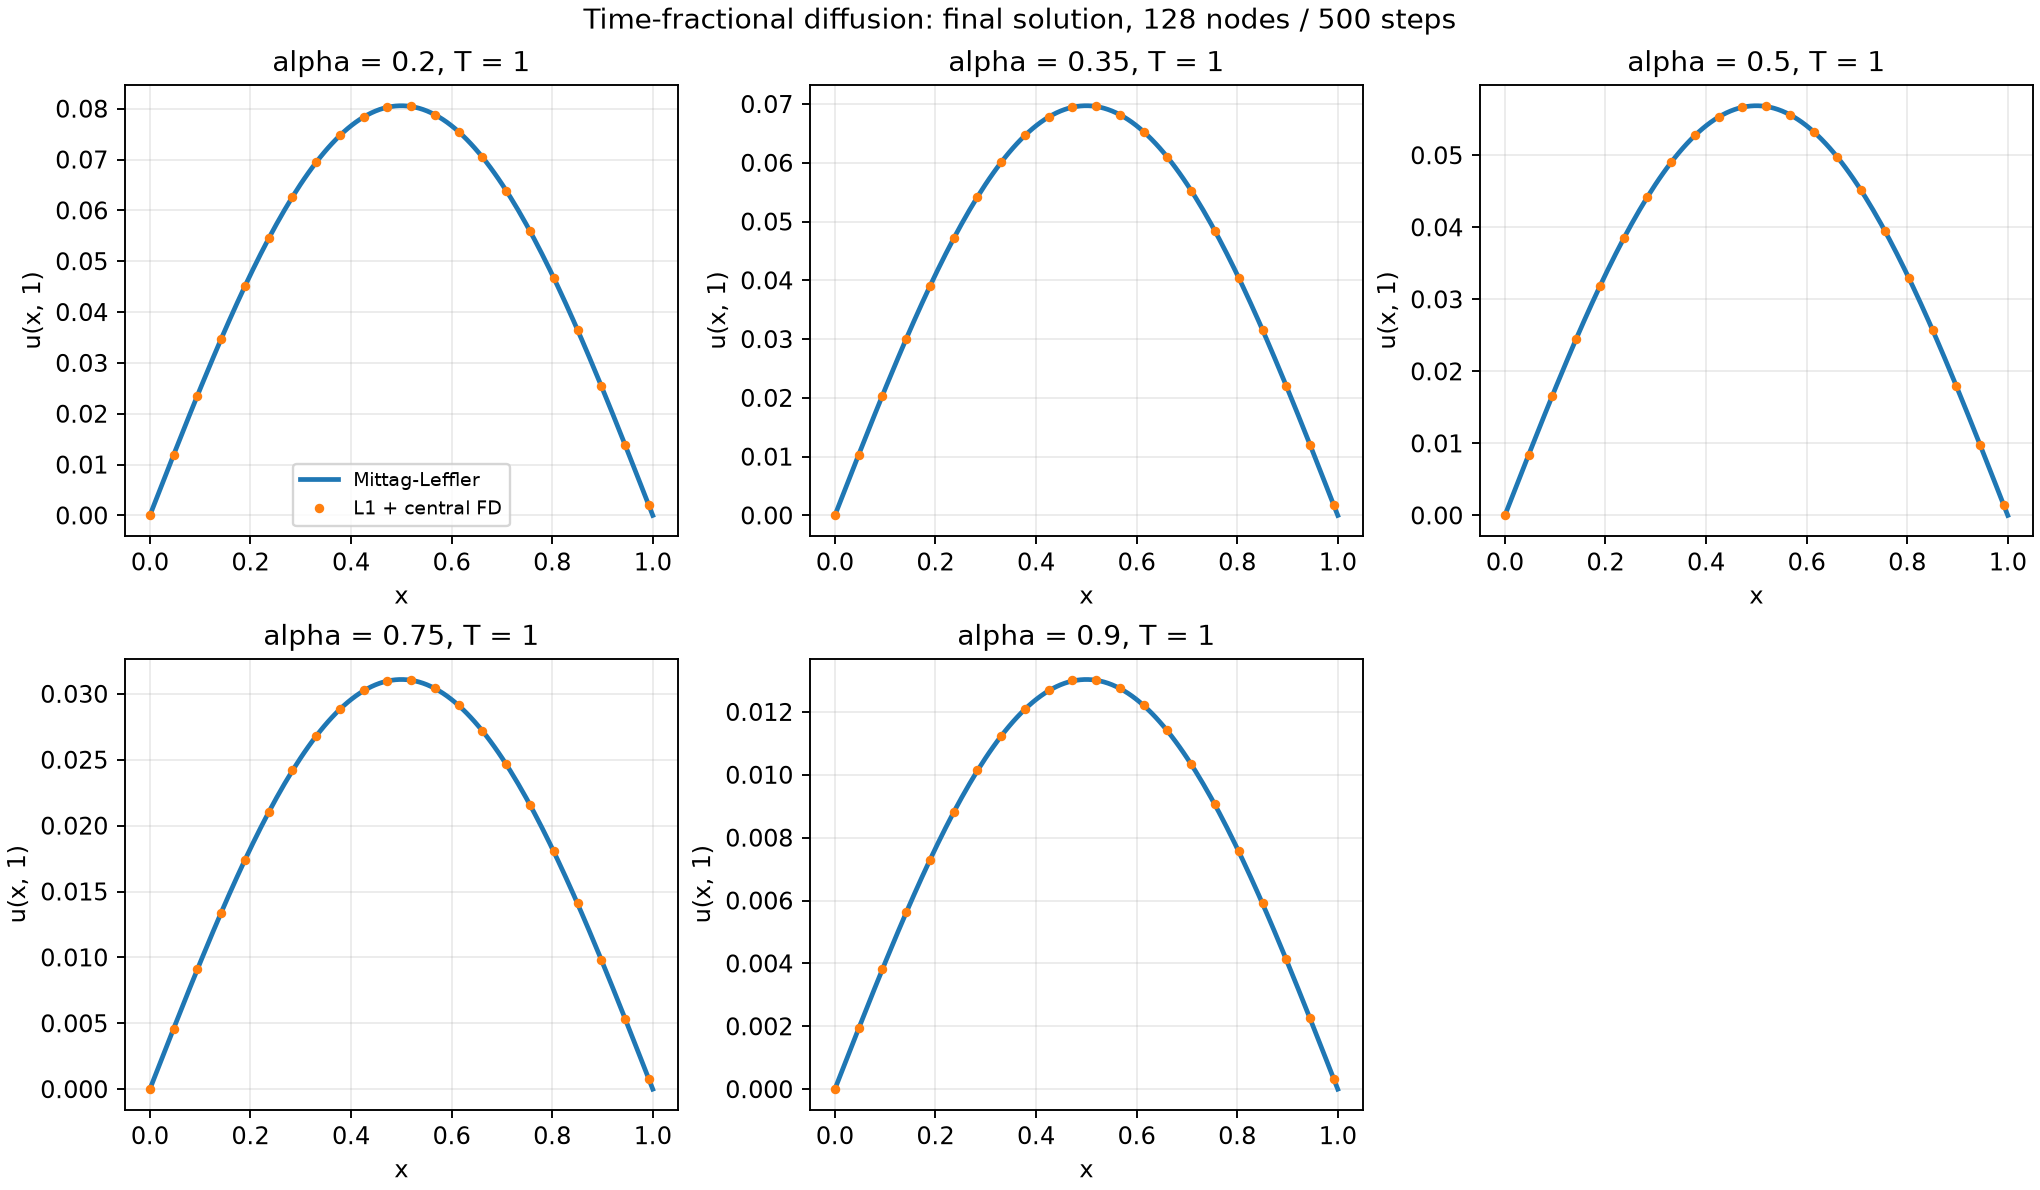

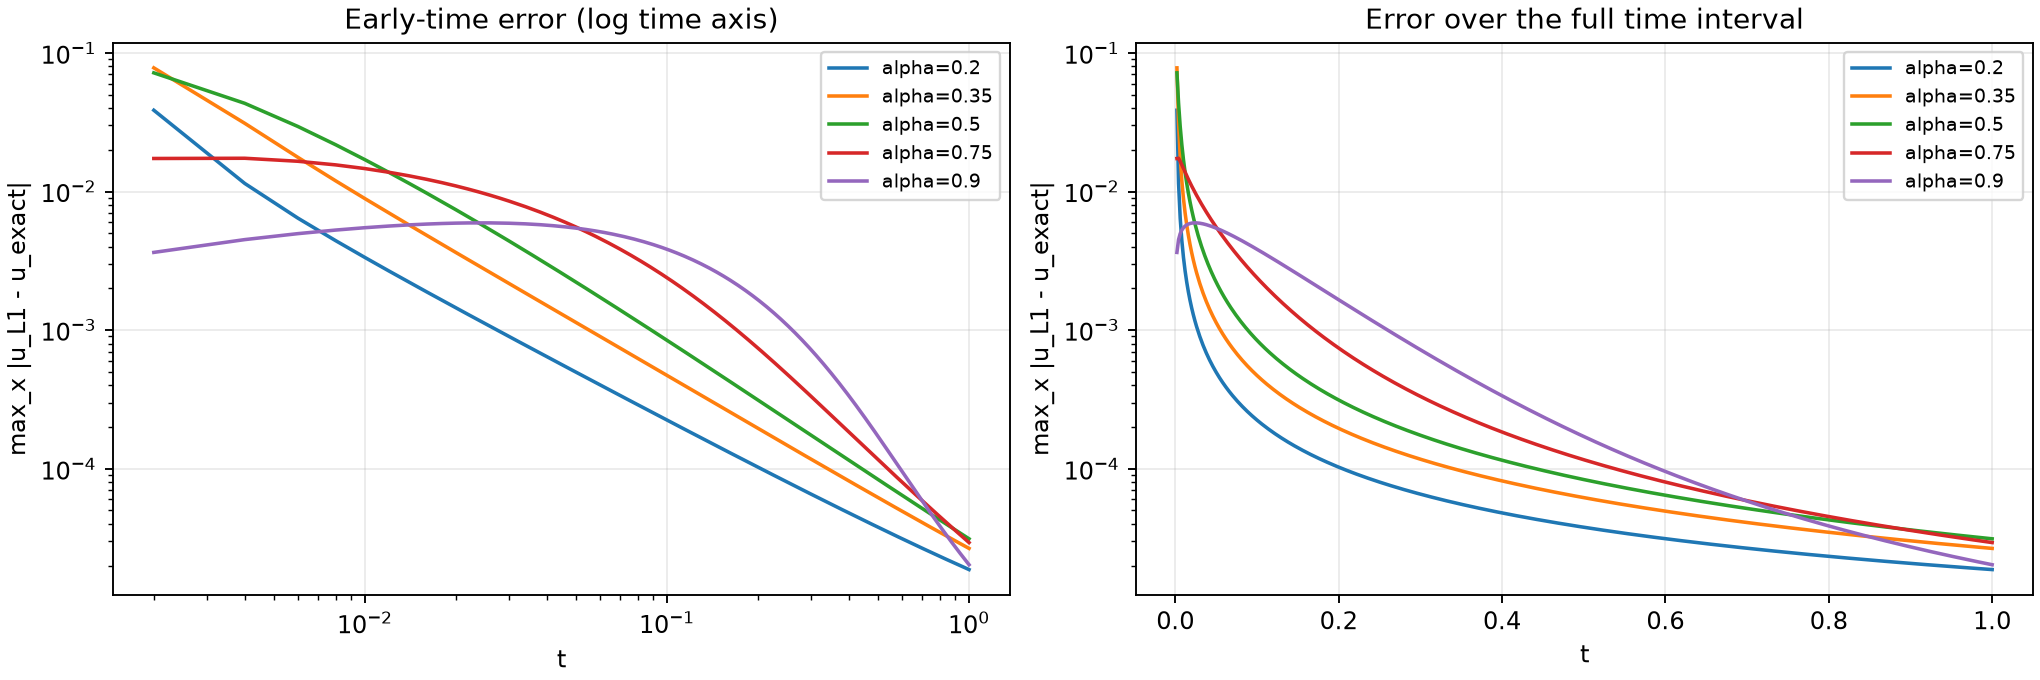

In [3]:
display(Image(filename=str(ROOT / 'results' / 'solution_comparison.png')))
display(Image(filename=str(ROOT / 'results' / 'error_vs_time.png')))

## Сходимость

Временную ошибку отделяем от пространственной: сравниваем L1 с точным временным решением пространственно дискретной системы, используя дискретное собственное значение. Для пространственной ошибки сравниваем точное временное распространение дискретной и непрерывной моделей. Это позволяет избежать маскировки временной ошибки пространственной. Проверки проводятся при T=1; порядок для гладких решений не переносим автоматически на ошибку у t=0.

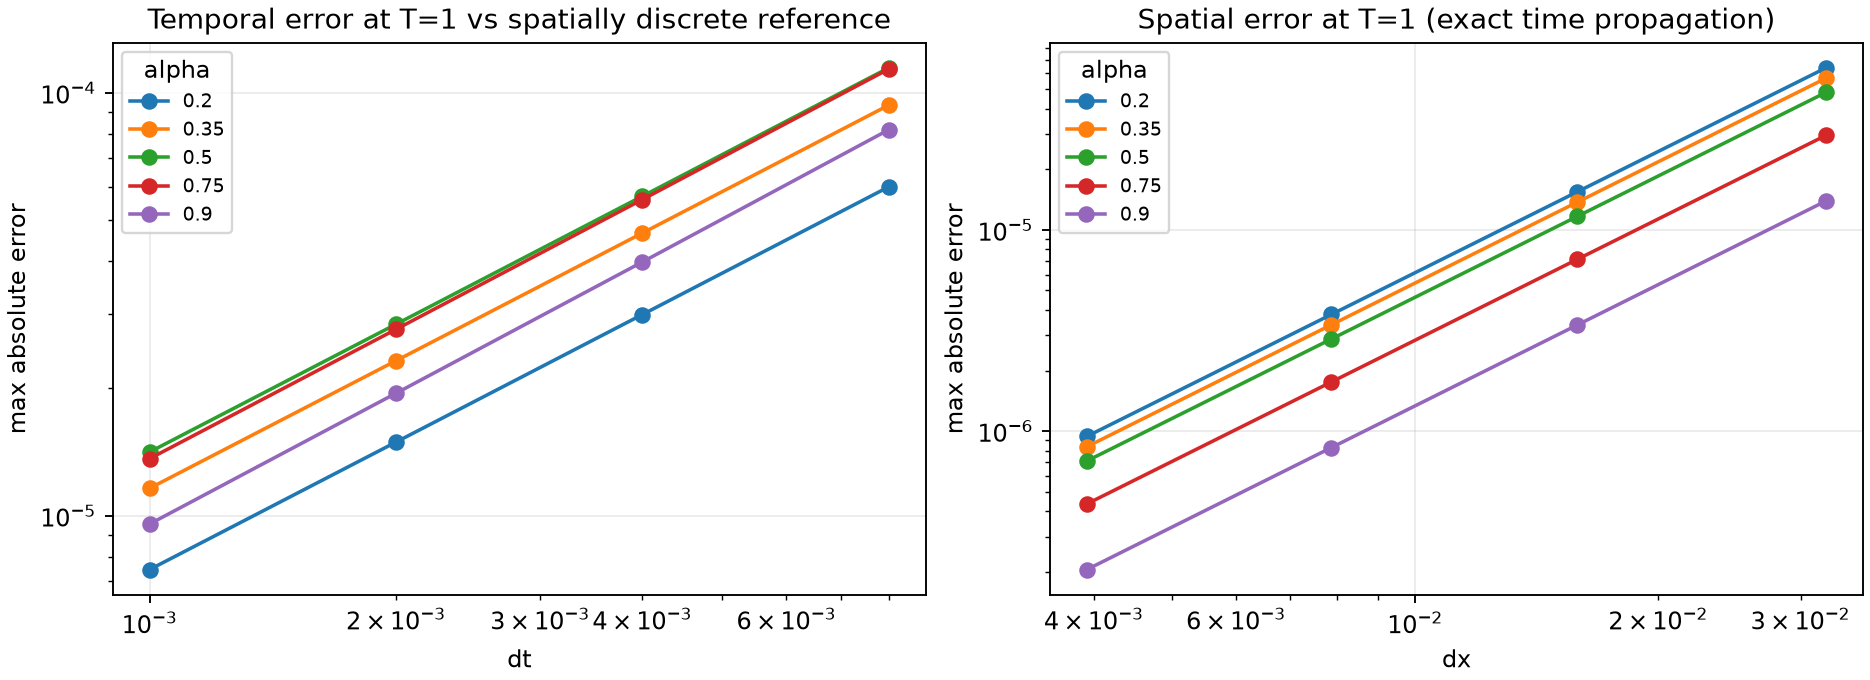

In [4]:
display(Image(filename=str(ROOT / 'results' / 'convergence.png')))

## Датасет

$u_0(x)=\sum_{k=1}^{8}a_k\sin(k\pi x)$; сначала $a_k\sim N(0,1)/k^{1.5}$, затем нормировка $\max_x|u_0|=1$. Seed: 20261016.

1000 обучающих примеров, 100 обычных тестовых, по 50 тестовых при α=0.35 и α=0.75. Фиксированные α отсутствуют в обучении, но находятся внутри диапазона обучения: это интерполяция по α.

Метки получены L1-схемой с центральными разностями. Ускорение использует точную диагонализацию дискретного пространственного оператора в синусном базисе, а не аналитическое решение непрерывного уравнения.

In [5]:
with np.load(ROOT / 'data' / 'dataset.npz', allow_pickle=False) as d:
    u0, alpha, uT, split, x = [d[key] for key in ['u0', 'alpha', 'uT', 'split', 'x']]
    metadata = json.loads(d['metadata'].item())
print('u0:', u0.shape, 'alpha:', alpha.shape, 'uT:', uT.shape)
print('Части выборки:', dict(zip(*np.unique(split, return_counts=True))))
train = split == 'train'
test = ~train
assert train.sum() == 1000 and test.sum() == 200
assert not np.isin(alpha[train], [0.35, 0.75]).any()
print('Все массивы конечны:', all(np.isfinite(a).all() for a in [u0, alpha, uT]))
print('Метаданные:', metadata)

u0: (1200, 128) alpha: (1200,) uT: (1200, 128)
Части выборки: {np.str_('test_alpha_035'): np.int64(50), np.str_('test_alpha_075'): np.int64(50), np.str_('test_random'): np.int64(100), np.str_('train'): np.int64(1000)}
Все массивы конечны: True
Метаданные: {'seed': 20261016, 'n_x': 128, 'n_steps': 500, 'T': 1.0, 'n_modes': 8, 'alpha_range': [0.2, 0.9], 'coefficient_distribution': 'Normal(0,1)/k^1.5; max(abs(u0))=1', 'method': 'implicit L1 in time, central differences in space; discrete sine diagonalization', 'split_counts': {'test_alpha_035': 50, 'test_alpha_075': 50, 'test_random': 100, 'train': 1000}}


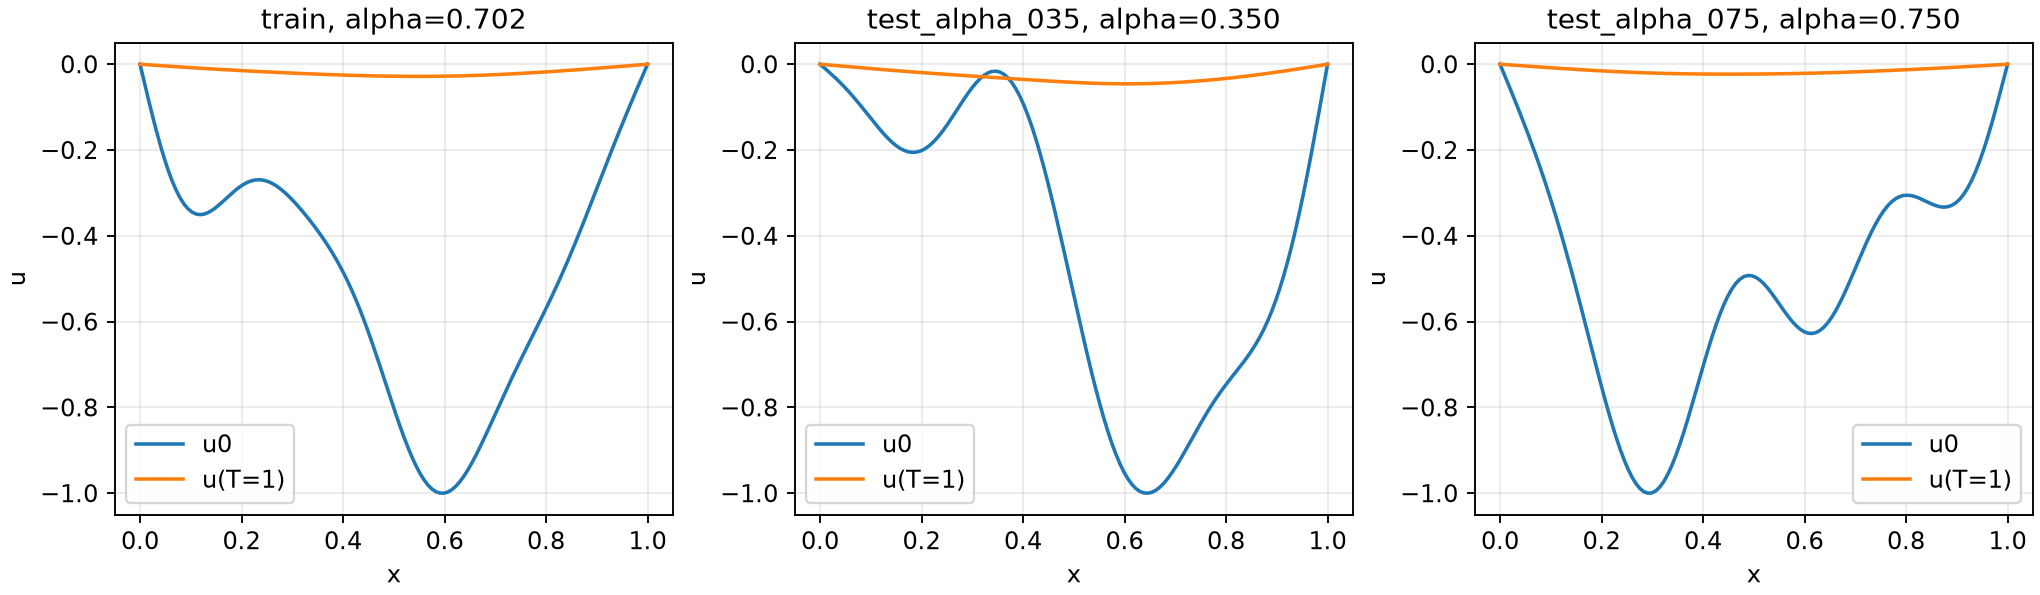

In [6]:
display(Image(filename=str(ROOT / 'results' / 'dataset_examples.png')))

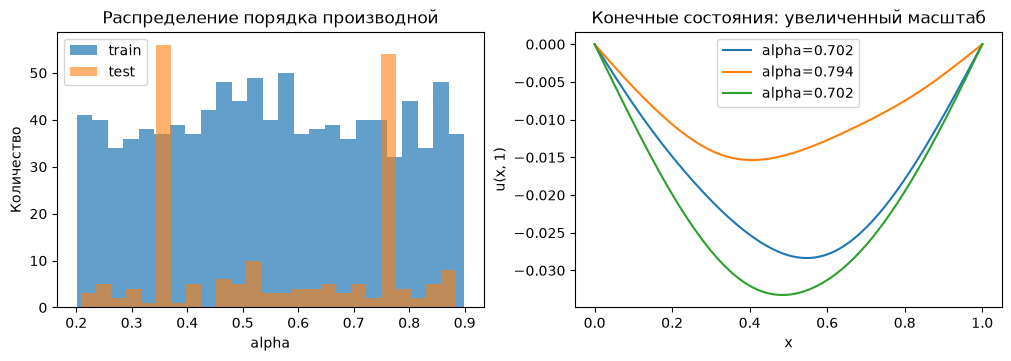

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
axes[0].hist(alpha[train], bins=25, label='train', alpha=.7)
axes[0].hist(alpha[test], bins=25, label='test', alpha=.6)
axes[0].set(xlabel='alpha', ylabel='Количество', title='Распределение порядка производной')
axes[0].legend()
for i in [0, 1, 2]:
    axes[1].plot(x, uT[i], label=f'alpha={alpha[i]:.3f}')
axes[1].set(xlabel='x', ylabel='u(x, 1)', title='Конечные состояния: увеличенный масштаб')
axes[1].legend()
plt.show()

## Границы результата

Подготовлены численный решатель, проверка и датасет конечных состояний. Нейросеть не обучалась. Тестовые начальные условия имеют то же распределение, что и обучающие; экстраполяция по α не проверяется. Для всех входов используется восемь синусных мод, поэтому датасет не покрывает произвольные начальные условия. Начальная нормировка должна учитываться в дальнейшем ML-эксперименте.